# Part 2: Bayesian Probability on IMDb Movie Reviews
**Formative 3 - Probability Distributions, Bayesian Probability, and Gradient Descent Implementation**

**Question:** if a review contains a given keyword, how likely is it to be positive?

**Our choice:** we compute **P(Positive | keyword)** only, as the assignment requires (not both directions).

**Method:** Bayes' theorem implemented with basic Python only (`csv` and `re`). A keyword is counted once per review.

$$P(\text{Positive}\mid kw)=\frac{P(kw\mid \text{Positive})\;P(\text{Positive})}{P(kw)}$$

| Term | Meaning |
|---|---|
| Prior `P(Positive)` | share of all reviews that are positive, before looking at any word |
| Likelihood `P(kw\|Positive)` | among positive reviews, the share containing the keyword |
| Marginal `P(kw)` | among all reviews, the share containing the keyword |
| Posterior `P(Positive\|kw)` | among reviews containing the keyword, the share that are positive |

## 1. Setup (works locally and on Colab)

In [1]:
import os, sys, subprocess

REPO = "https://github.com/igorntwari/ml-formative-3-probability-bayes-gradient-descent.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB and not os.path.exists("bayes_imdb.py"):
    subprocess.run(["git", "clone", REPO], check=True)
    os.chdir("ml-formative-3-probability-bayes-gradient-descent/part2_bayesian")

CSV = "IMDB Dataset.csv"
if not os.path.exists(CSV):
    if IN_COLAB:
        from google.colab import files
        print("Upload IMDB Dataset.csv")
        files.upload()
    else:
        raise FileNotFoundError("Put 'IMDB Dataset.csv' next to this notebook (part2_bayesian/).")

print("Working dir:", os.getcwd())

Working dir: /mnt/c/Users/Alieu O Jobe/ml-formative-3-probability-bayes-gradient-descent/part2_bayesian


## 2. Load the data

In [2]:
from bayes_imdb import *

reviews = load_reviews(CSV)
n_total = len(reviews)
n_pos = sum(1 for _, label in reviews if label == "positive")
print(f"Reviews: {n_total} | positive: {n_pos} | negative: {n_total - n_pos}")
print(f"Prior P(Positive) = {n_pos / n_total:.4f}")

Reviews: 50000 | positive: 25000 | negative: 25000
Prior P(Positive) = 0.5000


## 3. Keywords and justification

**Positive keywords**

| Keyword | Why we chose it | P(Positive\|kw) |
|---|---|---|
| excellent | Direct praise of quality that reviewers use on their own, and common (7.1% of reviews), so the estimate is stable | 0.8073 |
| wonderful | A strong, general positive word that is not tied to a genre or topic, and it appears in 5.6% of reviews | 0.8120 |
| superb | A formal, emphatic word that people use almost only to praise something, and it gave the highest posterior of the common positive words | 0.8557 |
| amazing | A very common everyday praise word (4.3% of reviews) that shows how people express enthusiasm in informal reviews | 0.7783 |

**Negative keywords**

| Keyword | Why we chose it | P(Positive\|kw) |
|---|---|---|
| worst | A superlative complaint that is the most frequent strong negative word (8.9% of reviews), so it gives the most reliable estimate | 0.0924 |
| awful | A direct negative judgment of quality that rarely appears in positive reviews | 0.0977 |
| terrible | Similar to "awful" but a different word, which shows the pattern is not tied to one word | 0.1413 |
| waste | Comes from phrases like "waste of time" and "waste of money", the way viewers say a film was not worth watching, and it had the lowest posterior | 0.0687 |

**How we chose them:** we looked at which words appear in many reviews and are strongly tied to one sentiment, and kept words that mean something on their own. We avoided words that are strong only because of a phrase (like "redeeming" from "no redeeming qualities") or that carry no sentiment (like "journey" or "today"). Every chosen word appears in more than 1,000 reviews, so the probabilities are stable.

In [3]:
print("Positive:", POSITIVE_KEYWORDS)
print("Negative:", NEGATIVE_KEYWORDS)

Positive: ['excellent', 'wonderful', 'superb', 'amazing']
Negative: ['worst', 'awful', 'terrible', 'waste']


## 4. Probability table (prior, likelihood, marginal, posterior)

In [4]:
keywords = POSITIVE_KEYWORDS + NEGATIVE_KEYWORDS
results = [analyze_keyword(reviews, k, n_total, n_pos) for k in keywords]
print_table(results)

| Keyword | P(Positive) | P(kw\|Positive) | P(kw) | P(Positive\|kw) |
|---|---|---|---|---|
| excellent | 0.5000 | 0.1146 | 0.0710 | 0.8073 |
| wonderful | 0.5000 | 0.0902 | 0.0555 | 0.8120 |
| superb | 0.5000 | 0.0410 | 0.0240 | 0.8557 |
| amazing | 0.5000 | 0.0671 | 0.0431 | 0.7783 |
| worst | 0.5000 | 0.0164 | 0.0886 | 0.0924 |
| awful | 0.5000 | 0.0112 | 0.0575 | 0.0977 |
| terrible | 0.5000 | 0.0152 | 0.0539 | 0.1413 |
| waste | 0.5000 | 0.0070 | 0.0507 | 0.0687 |


## 5. Verification: Bayes result vs direct count
The posterior must equal (positive reviews with the word) / (all reviews with the word).

In [5]:
print(f"{'keyword':<12}{'bayes':>10}{'direct':>10}  match")
for r in results:
    direct = direct_posterior(reviews, r["keyword"])
    ok = abs(r["posterior"] - direct) < 1e-9
    print(f"{r['keyword']:<12}{r['posterior']:>10.4f}{direct:>10.4f}  {ok}")
    assert ok, f"Mismatch for {r['keyword']}"
print("All keywords verified.")

keyword          bayes    direct  match
excellent       0.8073    0.8073  True
wonderful       0.8120    0.8120  True
superb          0.8557    0.8557  True
amazing         0.7783    0.7783  True
worst           0.0924    0.0924  True
awful           0.0977    0.0977  True
terrible        0.1413    0.1413  True
waste           0.0687    0.0687  True
All keywords verified.


## 6. Chart: posterior vs the 0.5 starting rate

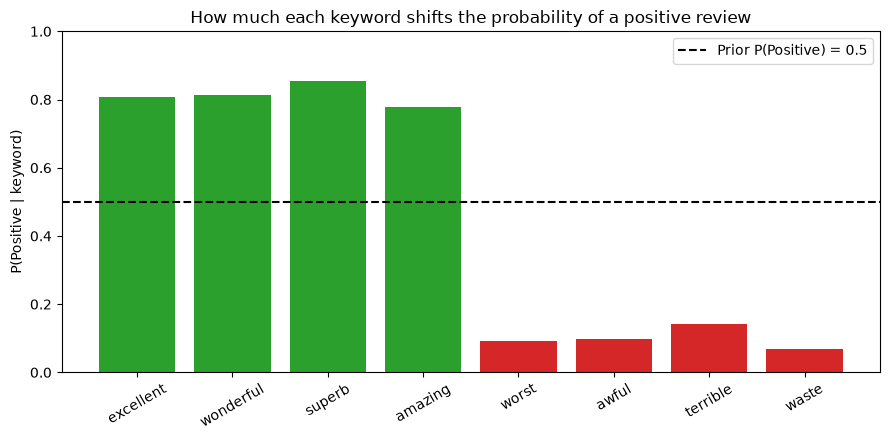

In [6]:
import matplotlib.pyplot as plt

words = [r["keyword"] for r in results]
posts = [r["posterior"] for r in results]
colors = ["tab:green" if w in POSITIVE_KEYWORDS else "tab:red" for w in words]

plt.figure(figsize=(9, 4.5))
plt.bar(words, posts, color=colors)
plt.axhline(0.5, color="black", linestyle="--", label="Prior P(Positive) = 0.5")
plt.ylabel("P(Positive | keyword)")
plt.title("How much each keyword shifts the probability of a positive review")
plt.ylim(0, 1)
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("posterior_chart.png", dpi=150)
plt.show()

## 7. Interpretation

In [7]:
for r in results:
    shift = (r["posterior"] - r["prior"]) * 100
    direction = "above" if shift > 0 else "below"
    print(f"- '{r['keyword']}' appears in {r['marginal']:.1%} of reviews. "
          f"{r['posterior']:.1%} of those are positive, {abs(shift):.1f} points {direction} the 50% baseline.")

- 'excellent' appears in 7.1% of reviews. 80.7% of those are positive, 30.7 points above the 50% baseline.
- 'wonderful' appears in 5.6% of reviews. 81.2% of those are positive, 31.2 points above the 50% baseline.
- 'superb' appears in 2.4% of reviews. 85.6% of those are positive, 35.6 points above the 50% baseline.
- 'amazing' appears in 4.3% of reviews. 77.8% of those are positive, 27.8 points above the 50% baseline.
- 'worst' appears in 8.9% of reviews. 9.2% of those are positive, 40.8 points below the 50% baseline.
- 'awful' appears in 5.8% of reviews. 9.8% of those are positive, 40.2 points below the 50% baseline.
- 'terrible' appears in 5.4% of reviews. 14.1% of those are positive, 35.9 points below the 50% baseline.
- 'waste' appears in 5.1% of reviews. 6.9% of those are positive, 43.1 points below the 50% baseline.


**Reading the results**

- Positive keywords push the probability well above 0.5, negative keywords well below it.
- The marginal `P(kw)` is in the denominator because we condition on reviews that contain the word, so we divide by how common the word is overall.
- A common word that appears equally in both classes (for example "good", about 0.49) gives almost no information, even though its likelihood is high.

**Limitations**
- Negation ("not good") and sarcasm are not handled, because we look at one word at a time.
- Rare words give unstable estimates, so we chose words that appear in thousands of reviews.
- Keywords were chosen using the same dataset they are evaluated on, so the numbers describe this dataset, not all movie reviews.

## 8. Save the results

In [8]:
import csv
with open("part2_results.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["keyword", "prior", "likelihood", "marginal", "posterior"])
    w.writeheader()
    w.writerows(results)
print("Saved part2_results.csv and posterior_chart.png")

Saved part2_results.csv and posterior_chart.png
